<a href="https://colab.research.google.com/github/Moon-JB/26-2-DIP-202201276/blob/main/HW02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

과제 1번

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install nibabel

In [ ]:
import nibabel as nib

In [ ]:
import os, glob

data_dir = '/content/drive/MyDrive'   # 파일이 하위 폴더에 있다면 그 폴더 경로로 수정

# 드라이브 전체 검색이라 조금 걸릴 수 있습니다. 위치를 알면 생략해도 됩니다.
print(glob.glob(f'{data_dir}/**/volume-covid19-A-0700*', recursive=True))

['/content/drive/MyDrive/volume-covid19-A-0700_day000.nii.gz', '/content/drive/MyDrive/volume-covid19-A-0700_day015.nii.gz']


In [ ]:
import os
imgpath = '/content/drive/MyDrive/DIP4E/DIP4E'

In [ ]:
ct_base   = nib.load(f'{data_dir}/volume-covid19-A-0700_day000.nii.gz').get_fdata()
ct_FU     = nib.load(f'{data_dir}/volume-covid19-A-0700_day015.nii.gz').get_fdata()
ct_FU_reg = nib.load(f'{data_dir}/ volume-covid19-A-0700_day015-reg_to_day000.nii.gz').get_fdata()

print(ct_base.shape, ct_FU.shape, ct_FU_reg.shape)

(512, 512, 70) (512, 512, 67) (512, 512, 70)


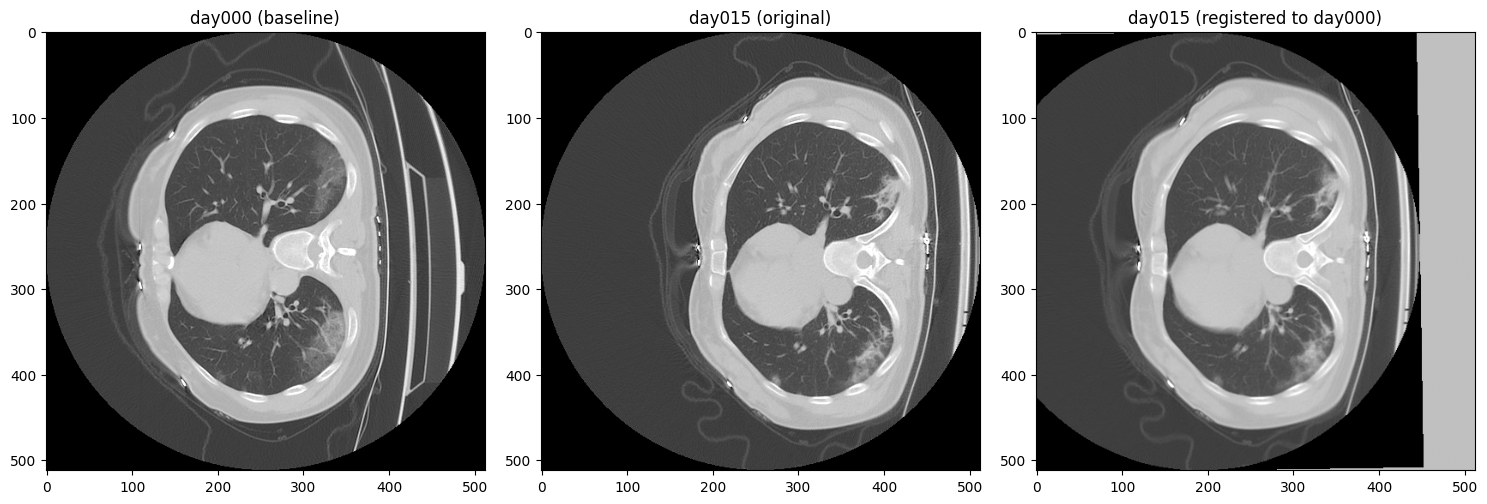

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(ct_base[:, :, 30], vmin=-1500, vmax=500, cmap='gray')
plt.title('day000 (baseline)')

plt.subplot(132)
plt.imshow(ct_FU[:, :, 30], vmin=-1500, vmax=500, cmap='gray')
plt.title('day015 (original)')

plt.subplot(133)
plt.imshow(ct_FU_reg[:, :, 30], vmin=-1500, vmax=500, cmap='gray')
plt.title('day015 (registered to day000)')

plt.tight_layout()
plt.show()

과제 2번

In [ ]:
f = plt.imread(imgpath+'/hidden-symbols.tif')

def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

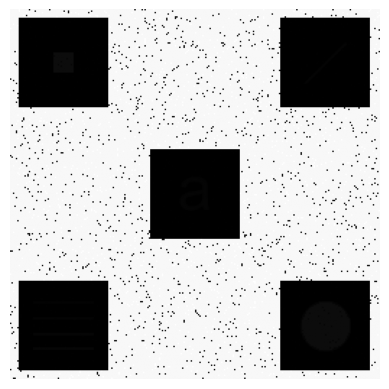

In [ ]:
f_eq = histogram_equalization(f)
plt.imshow(f_eq,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

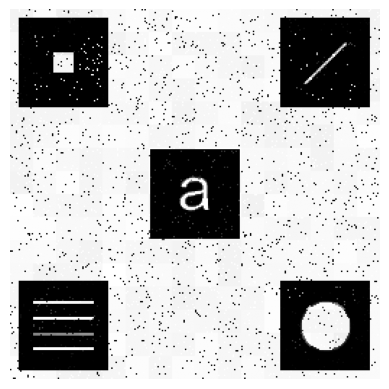

In [ ]:
N = 16
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()


과제 3번

In [ ]:
import scipy.signal as signal
from skimage import io

In [ ]:
f = io.imread('/content/drive/MyDrive/coffee.jpg',as_gray=True)[::2,::2]
print(f.shape,f.dtype)

(1451, 1066) float64


In [ ]:
import time

computation time =  0.14719486236572266  sec


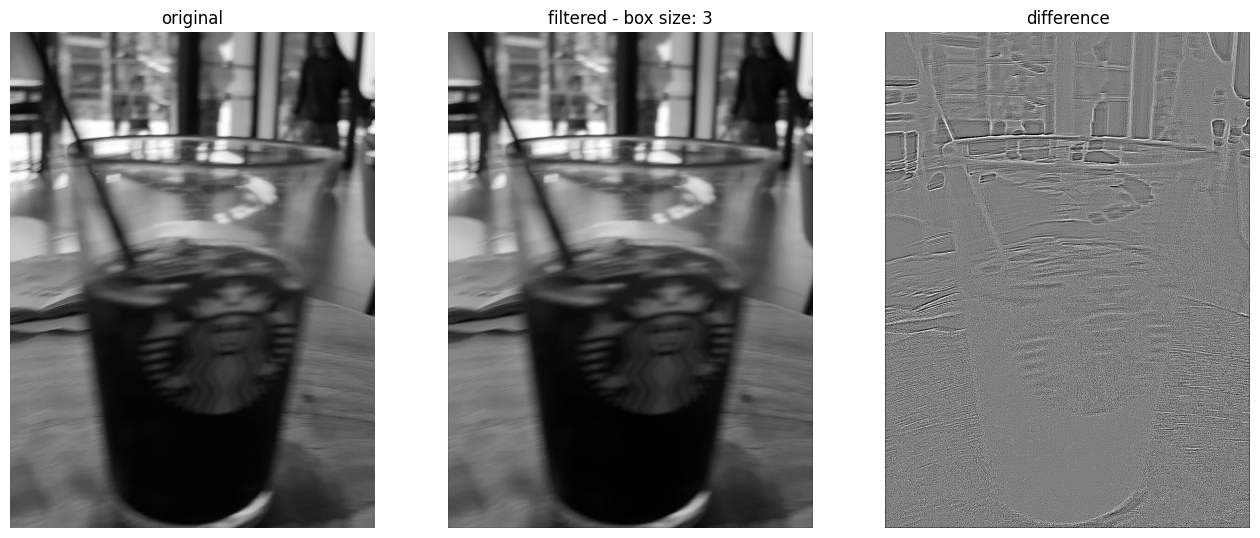

computation time =  0.22594237327575684  sec


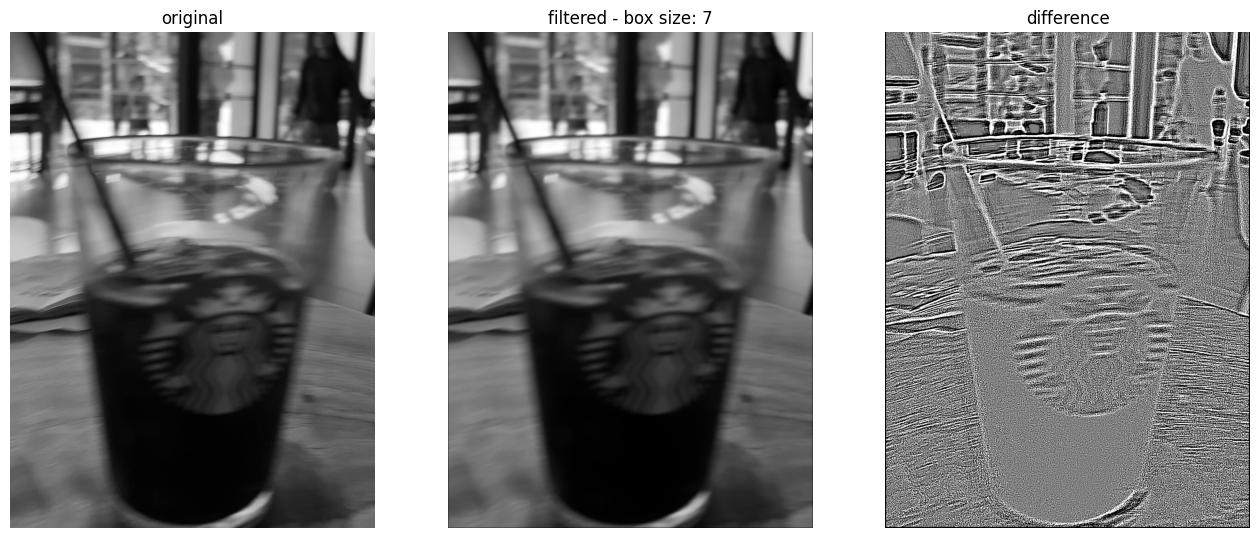

computation time =  0.8595016002655029  sec


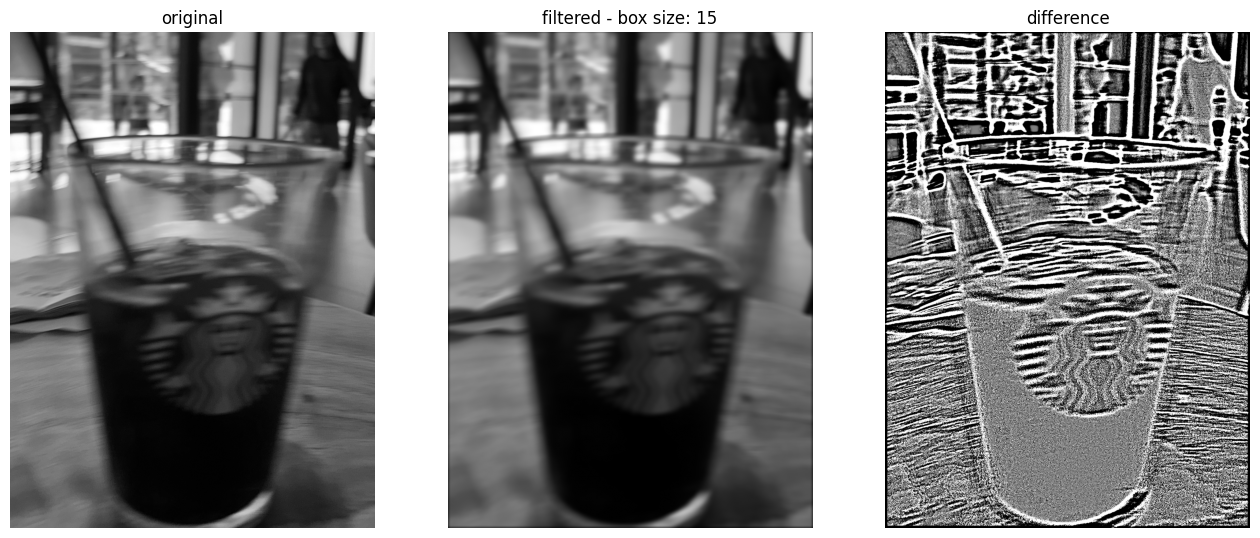

computation time =  3.120673179626465  sec


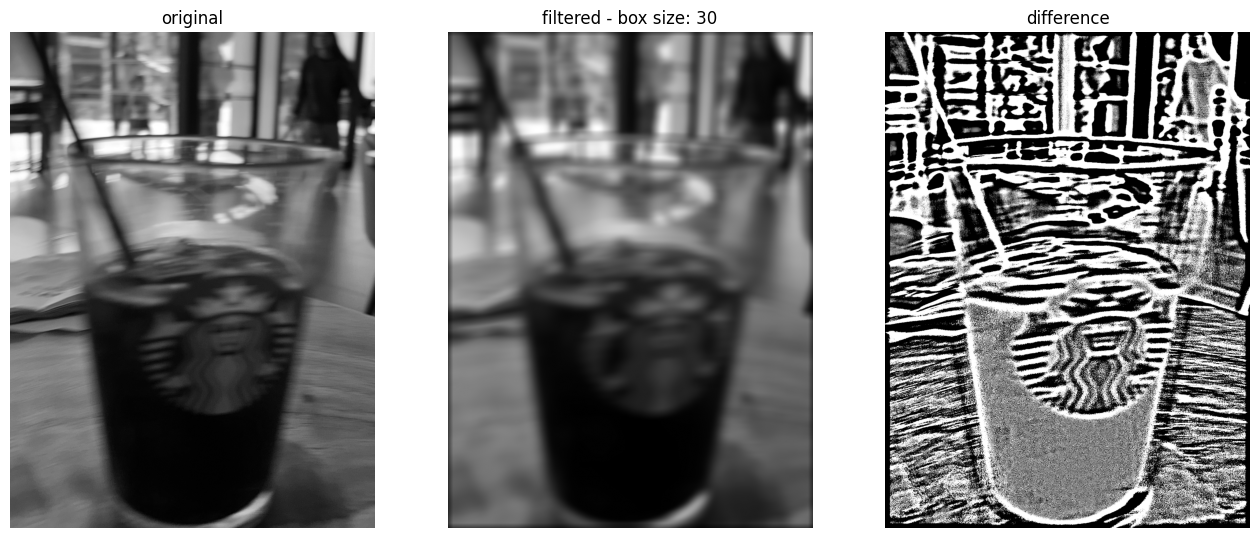

In [ ]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

과제 4번

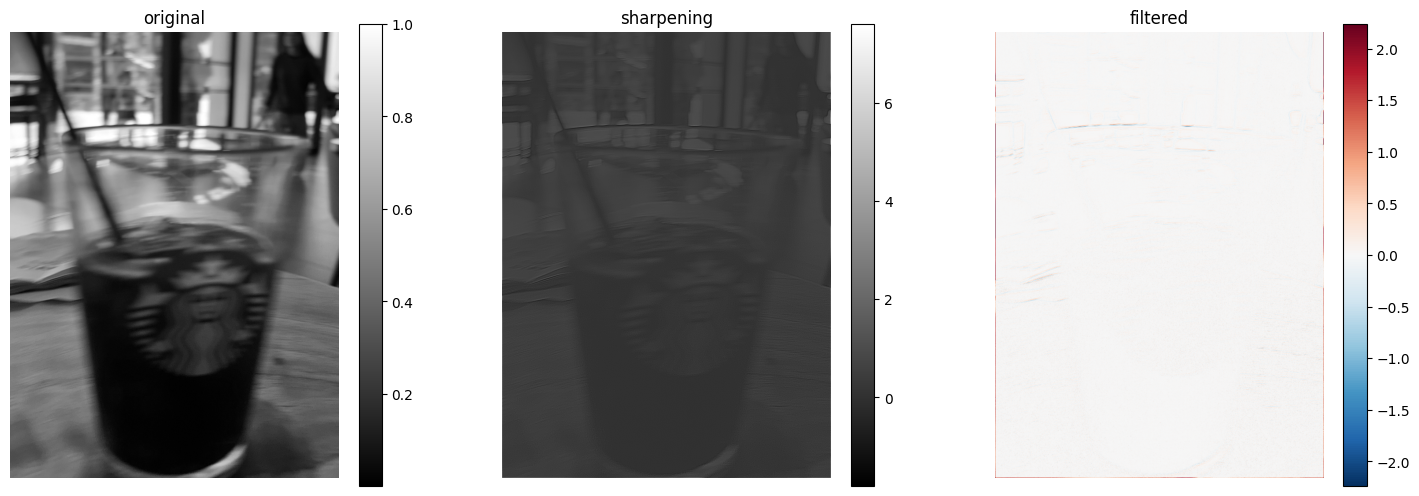

In [ ]:
f = io.imread('/content/drive/MyDrive/coffee.jpg',as_gray=True)[::3,::3]

w = np.array([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]])
y = signal.convolve2d(f,w,mode='same')
c = 1.5
g = f + c*(y)
plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('sharpening')
plt.subplot(133)
plt.imshow(y,cmap='RdBu_r',vmin=-0.5*np.max(np.abs(y)),vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()

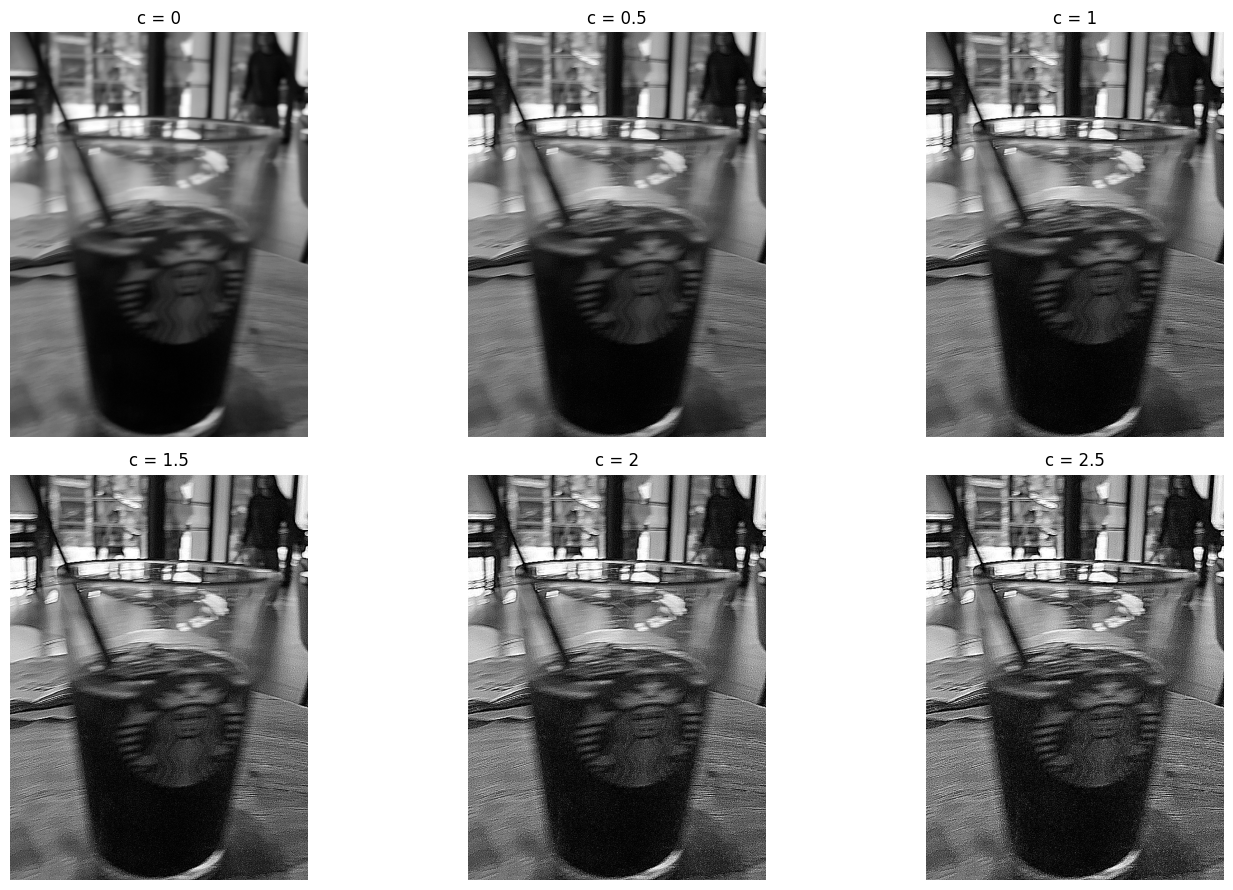

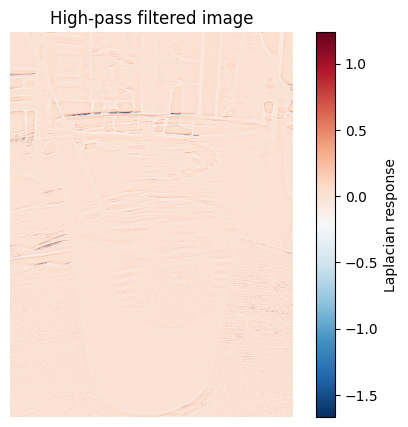

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from scipy import signal

# 1. 이미지 불러오기
f = io.imread(
    '/content/drive/MyDrive/coffee.jpg',
    as_gray=True
)[::4, ::4].astype(float)

# 2. Laplacian kernel
w = np.array([
    [-1, -1, -1],
    [-1, 8, -1],
    [-1, -1, -1]
], dtype=float)

# 3. High-pass filtering
y = signal.convolve2d(
    f, w, mode='same', boundary='symm'
)

# 4. 여러 c 값 비교
c_values = [0, 0.5, 1, 1.5, 2, 2.5]

fig, axes = plt.subplots(
    2, 3, figsize=(15, 9)
)

for ax, c in zip(axes.flat, c_values):
    g = f + c * y

    # 표시 범위 고정: 비교가 공정해짐
    ax.imshow(g, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'c = {c}')
    ax.axis('off')

plt.tight_layout()
plt.show()

# 5. 필터 응답 확인
plt.figure(figsize=(6, 5))
plt.imshow(y, cmap='RdBu_r')
plt.colorbar(label='Laplacian response')
plt.title('High-pass filtered image')
plt.axis('off')
plt.show()

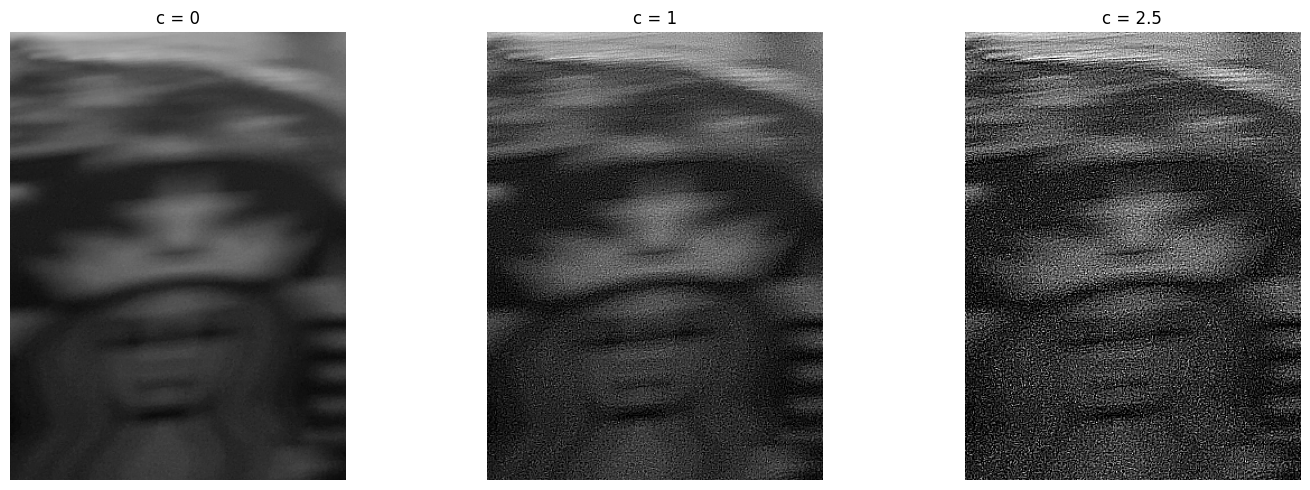

In [ ]:
# 예시: 이미지 중앙 부근을 잘라 확대
# 실제 로고 위치에 맞게 좌표를 조정해도 돼.
roi = (slice(600, 1000), slice(500, 800))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, c in zip(axes, [0, 1, 2.5]):
    g = f + c * y
    ax.imshow(g[roi], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'c = {c}')
    ax.axis('off')

plt.tight_layout()
plt.show()